# 02 — Exploratory Analysis

Class balance, sample appearance, capture-condition variation and split
composition. All figures are written to `evaluation/graphs/` and embedded here,
so the report and the notebook show the same images.


In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root by walking upward until config.py is found.  This is
# robust to the kernel's working directory being either the project root or the
# notebooks/ directory, which differs between nbconvert, JupyterLab and VS Code.
_here = Path.cwd().resolve()
ROOT = _here
for _cand in (_here, *_here.parents):
    if (_cand / "config.py").exists():
        ROOT = _cand
        break
else:
    raise RuntimeError(f"could not locate project root from {_here}")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib
import config

GRAPHS = "evaluation/graphs"
from IPython.display import Image, display, Markdown
from src.utils import load_json, fmt_bytes, imread_unicode

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
print("kernel cwd :", _here)
print("project root:", ROOT)
print("python      :", sys.version.split()[0])


kernel cwd : C:\Users\Sachin\OneDrive\Documents\Skanda's IPCV proj\Notebooks
project root: C:\Users\Sachin\OneDrive\Documents\Skanda's IPCV proj
python      : 3.12.16


In [2]:
from src.visualize import (
    plot_class_distribution, plot_resolution_and_size,
    plot_condition_distributions, plot_sample_grid, plot_split_composition,
)

inventory = pd.read_csv(config.METADATA_DIR / "image_inventory.csv")
split_summary = load_json(config.METADATA_DIR / "split_summary.json")
print(len(inventory), "images loaded")

6150 images loaded


## 1. Class distribution

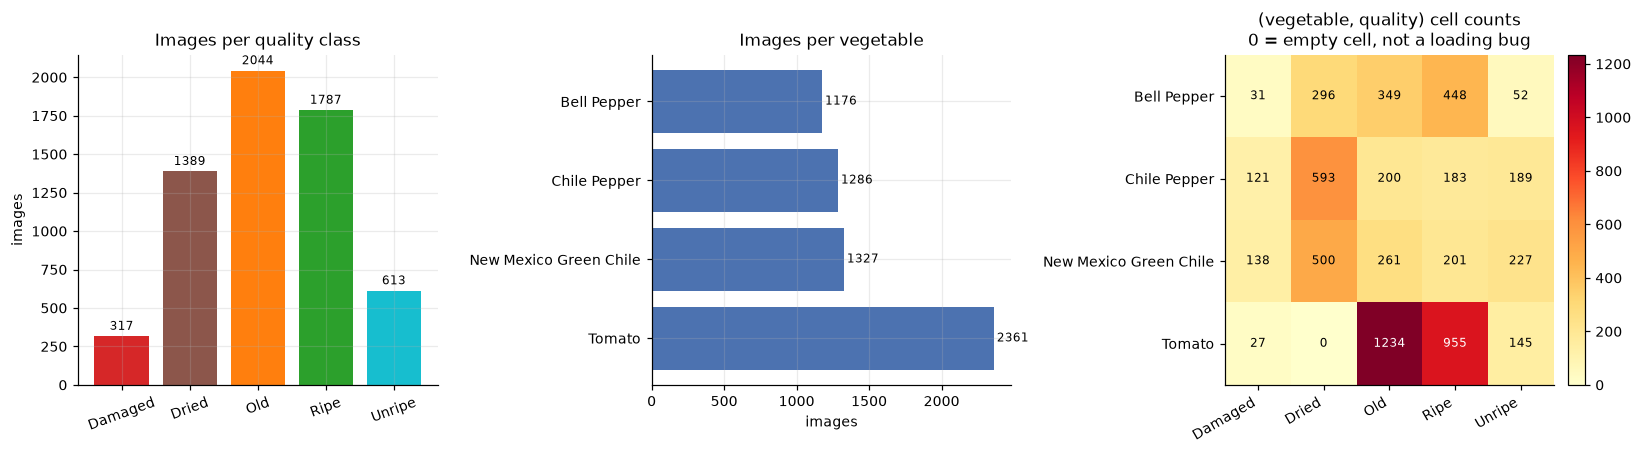

,count,share,vs largest
quality,,,
Damaged,317,5.15,6.45
Dried,1389,22.59,1.47
Old,2044,33.24,1.00
Ripe,1787,29.06,1.14
Unripe,613,9.97,3.33


In [3]:
fig = plot_class_distribution(inventory, out=ROOT / f"{GRAPHS}/eda_class_distribution.png")
display(Image(filename=str(ROOT / f"{GRAPHS}/eda_class_distribution.png")))

q = inventory["quality"].value_counts().reindex(config.QUALITY_CLASSES)
display(pd.DataFrame({
    "count": q, "share": (q / len(inventory) * 100).round(2),
    "vs largest": (q.max() / q).round(2),
}))

`Old` (2,044) and `Ripe` (1,787) together account for 62% of the corpus, while
`Damaged` (317) is 5%. A majority-class predictor that always answered "Old"
would score ~33% accuracy, which is the floor any real model must clear — and
the reason every table in this project leads with macro F1 rather than accuracy.


## 2. Resolution and file size

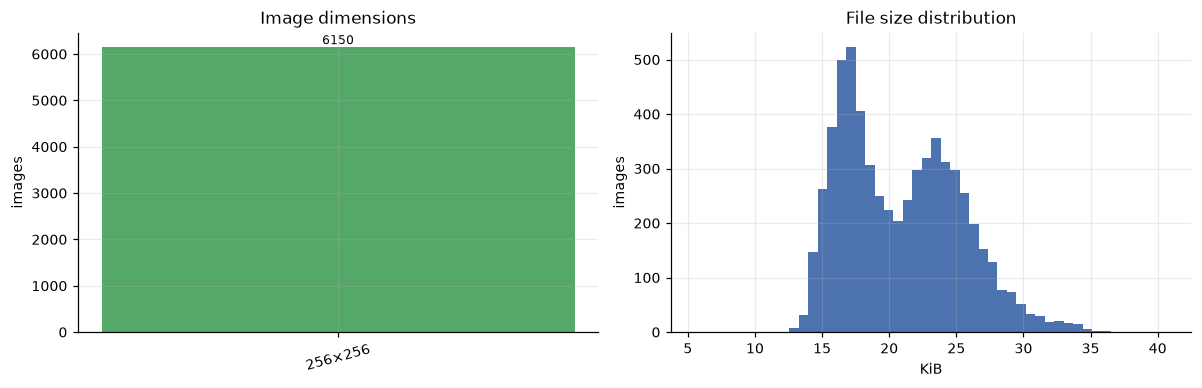

count     6150.0
mean     21404.6
std       4511.2
min       5654.0
25%      17484.0
50%      20939.0
75%      24722.0
max      41719.0
Name: file_size_bytes, dtype: float64


In [4]:
plot_resolution_and_size(inventory, out=ROOT / f"{GRAPHS}/eda_resolution_size.png")
display(Image(filename=str(ROOT / f"{GRAPHS}/eda_resolution_size.png")))
print(inventory["file_size_bytes"].describe().round(1))

## 3. Lighting, contrast and focus per class

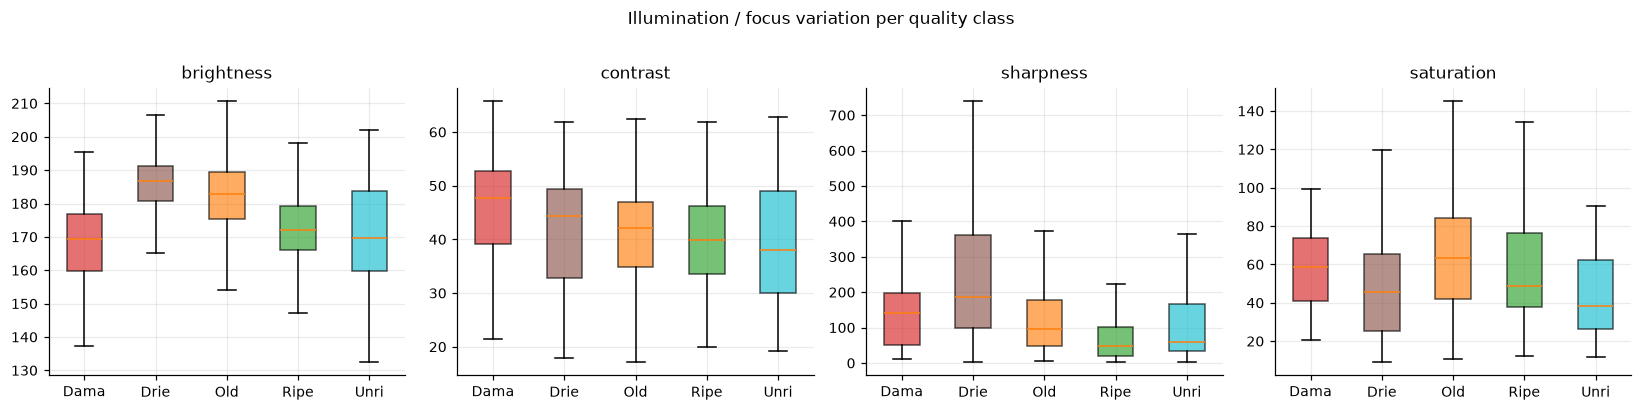

,brightness,contrast,sharpness,saturation
quality,,,,
Damaged,169.3,47.7,142.0,58.8
Dried,186.7,44.3,186.7,45.6
Old,182.8,42.0,95.7,63.3
Ripe,172.2,39.9,48.6,48.7
Unripe,169.8,38.1,59.4,38.6


In [5]:
plot_condition_distributions(inventory, out=ROOT / f"{GRAPHS}/eda_conditions.png")
display(Image(filename=str(ROOT / f"{GRAPHS}/eda_conditions.png")))

agg = inventory.groupby("quality")[["brightness", "contrast", "sharpness", "saturation"]].median()
display(agg.reindex(config.QUALITY_CLASSES).round(1))

Sharpness is markedly lower for `Dried` — dried specimens are wrinkled and
low-contrast, so the Laplacian responds weakly. That is a property of the object,
not a defect, but it means texture features carry real signal here (confirmed by
the feature screening in notebook 03).


## 4. Sample images

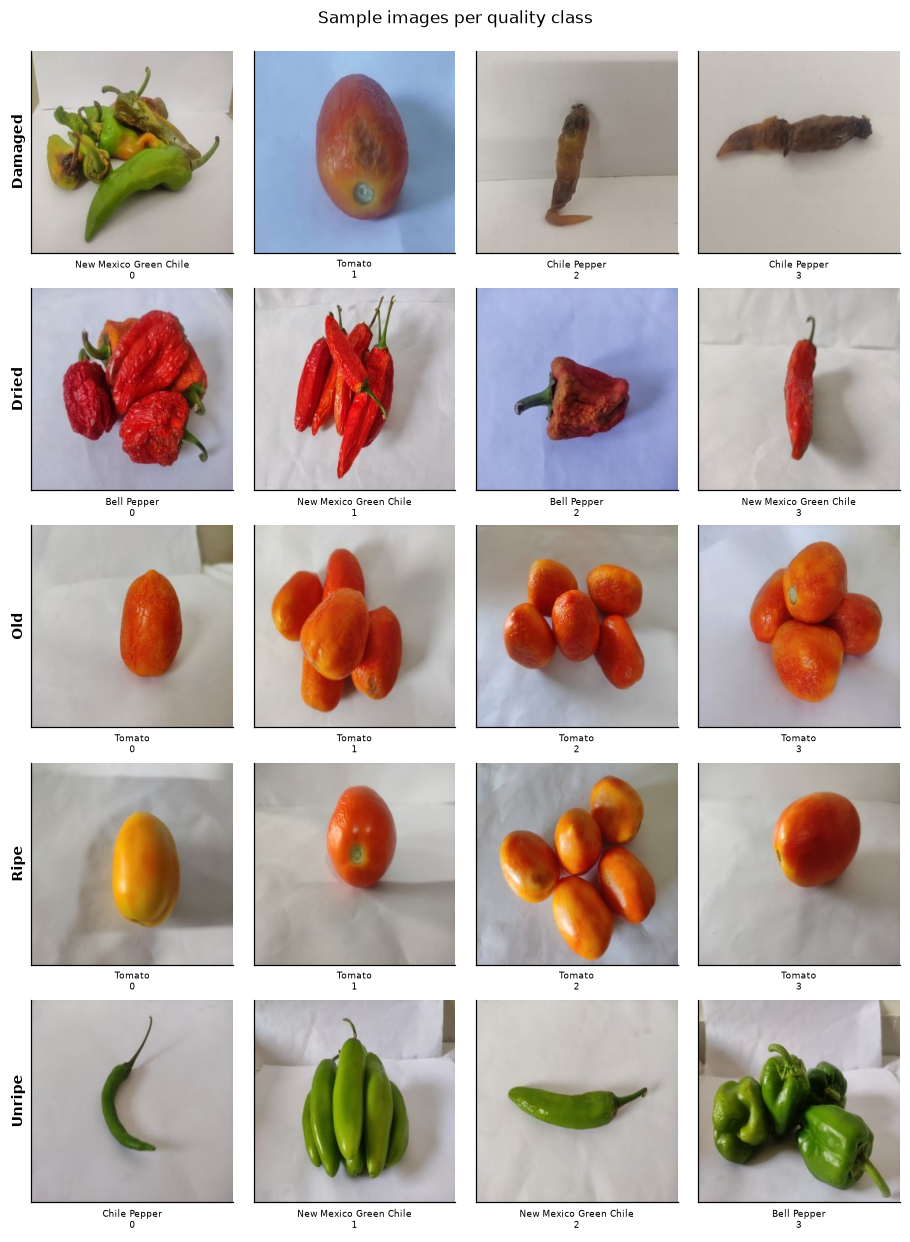

In [6]:
plot_sample_grid(inventory, n_per_class=4, out=ROOT / f"{GRAPHS}/eda_samples.png")
display(Image(filename=str(ROOT / f"{GRAPHS}/eda_samples.png")))

Visual inspection confirms the labels are semantically usable: `Ripe` specimens
are saturated and glossy, `Dried` are wrinkled and matte, `Old` show dulling and
shrivelling, `Unripe` are pale/green, `Damaged` show cuts and lesions.

It also shows why the task is hard at the boundary: `Old` and `Dried` grade into
each other, which is exactly the confusion the Phase 2 error analysis must
quantify.


## 5. Split composition

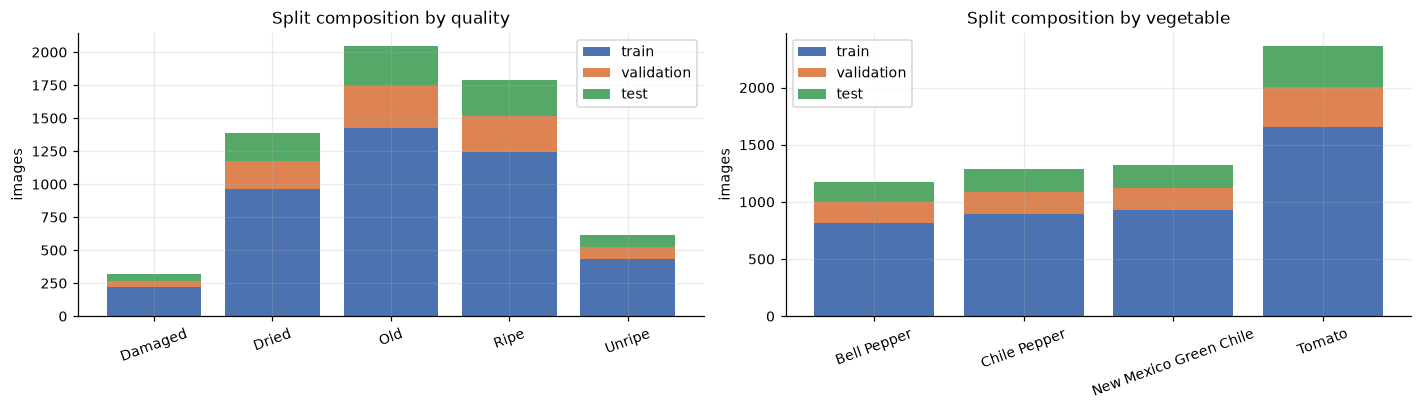

,split,images,fraction,requested
0,train,4286,0.6969,0.70
1,validation,929,0.1511,0.15
2,test,935,0.1520,0.15


groups spanning splits: 0
sha256 spanning splits: 0
duplicate groups in corpus: 4540


In [7]:
plot_split_composition(split_summary, out=ROOT / f"{GRAPHS}/eda_split_composition.png")
display(Image(filename=str(ROOT / f"{GRAPHS}/eda_split_composition.png")))

checks = split_summary["checks"]
display(pd.DataFrame({
    "split": list(config.SPLITS),
    "images": [checks["counts_per_split"][s] for s in config.SPLITS],
    "fraction": [checks["fractions"][s] for s in config.SPLITS],
    "requested": [config.SPLIT_RATIOS[s] for s in config.SPLITS],
}))
print("groups spanning splits:", checks["groups_spanning_splits"])
print("sha256 spanning splits:", checks["sha256_spanning_splits"])
print("duplicate groups in corpus:", checks["groups"])

The split is stratified on the joint (vegetable, quality) cell *and* grouped by
duplicate cluster. Every split contains all four vegetables and all five quality
classes, so per-class metrics on validation and test are meaningful even for the
27-image `Tomato/Damaged` cell — although anything computed on 27 images carries
a huge confidence interval, which the results report states explicitly.
